# IAU – Fáza 1: Prieskumná analýza dát

## Autori
- Sofiia Berehovykh – 50 %
- Viktoriia Bondarets – 50 %

## 1.1 Základný opis dát

### A. Analýza štruktúry dát

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Jupyter Notebook is working!")
print("Pandas version:", pd.__version__)

Jupyter Notebook is working!
Pandas version: 2.3.3


In [2]:
from pathlib import Path

if Path("data").is_dir():
    DATA_DIR = Path("data")
elif Path("../data").is_dir():
    DATA_DIR = Path("../data")
else:
    raise FileNotFoundError("Data folder not found")

units = pd.read_csv(DATA_DIR / "units.csv", sep=",")
gateways = pd.read_csv(DATA_DIR / "gateways.csv", sep=";")
readings = pd.read_csv(DATA_DIR / "readings.csv", sep="\t")

datasets = {
    "units": units,
    "gateways": gateways,
    "readings": readings
}

for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Number of records: {df.shape[0]}")
    print(f"Number of attributes: {df.shape[1]}")
    print(f"Attributes: {list(df.columns)}")


Dataset: units
Number of records: 2000
Number of attributes: 9
Attributes: ['year_commission', 'operatorOwner', 'number_serial', 'idDepot', 'codeLine', 'idUnit', 'serviceHours', 'code_model', 'dutyClass']

Dataset: gateways
Number of records: 16000
Number of attributes: 14
Attributes: ['modelHardware', 'Lon', 'macAddress', 'Lat', 'lastSeen', 'signalDbm', 'ipv4', 'dateInstall', 'idDepot', 'Vendor', 'idUnit', 'id_gateway', 'versionFirmware', 'Technician']

Dataset: readings
Number of records: 15041
Number of attributes: 11
Attributes: ['idUnit', 'tsCycle', 'currentMotor', 'dp_filter', 'temperatureOil', 'pressure_reservoir', 'pressure_oil', 'rms_vibration', 'Flowmeter', 'discharge_dewpoint', 'failure']


In [3]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")

    df.info()

    display(df.head())


--- UNITS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year_commission  2000 non-null   int64  
 1   operatorOwner    2000 non-null   object 
 2   number_serial    2000 non-null   object 
 3   idDepot          2000 non-null   int64  
 4   codeLine         2000 non-null   object 
 5   idUnit           2000 non-null   int64  
 6   serviceHours     1900 non-null   float64
 7   code_model       2000 non-null   object 
 8   dutyClass        2000 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 140.8+ KB


,year_commission,operatorOwner,number_serial,idDepot,codeLine,idUnit,serviceHours,code_model,dutyClass
0,2023,Rodrigues,DN-3078-09712,79,L6,1,4341.3,APU-20,L
1,2023,Klapp,XL-3043-34738,93,L5,2,5285.7,XC-7,heavy
2,2021,Kensy GmbH & Co. KGaA,GW-1240-18467,106,L4,3,10698.0,APU-20,H
3,2019,Silva,TE-2427-56403,6,L6,4,18617.3,APU-12,light
4,2020,Chapman-Franklin,AJ-1790-15374,17,L5,5,16261.2,XC-7,1



--- GATEWAYS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   modelHardware    16000 non-null  object 
 1   Lon              16000 non-null  float64
 2   macAddress       16000 non-null  object 
 3   Lat              16000 non-null  float64
 4   lastSeen         16000 non-null  object 
 5   signalDbm        16000 non-null  float64
 6   ipv4             16000 non-null  object 
 7   dateInstall      16000 non-null  object 
 8   idDepot          16000 non-null  int64  
 9   Vendor           16000 non-null  object 
 10  idUnit           2000 non-null   float64
 11  id_gateway       16000 non-null  object 
 12  versionFirmware  16000 non-null  object 
 13  Technician       16000 non-null  object 
dtypes: float64(4), int64(1), object(9)
memory usage: 1.7+ MB


,modelHardware,Lon,macAddress,Lat,lastSeen,signalDbm,ipv4,dateInstall,idDepot,Vendor,idUnit,id_gateway,versionFirmware,Technician
0,GWX-100,-8.78771,e9:57:6f:a6:6c:4d,39.43900,2024-03-06,-69.3,28.245.203.250,25 Jun 2022,27,Neves Cruz e Filhos,678.0,GW-00000,v3.4.1,Laura Miller
1,NODE-7,-8.75647,d6:23:2d:fb:d4:9a,38.67629,2024/04/26,-60.9,98.152.214.93,05 Jul 2023,119,Schlosser,1970.0,GW-00001,v1.2.5,Dr. Jane Etzold B.Eng.
2,GWX-100,-6.28849,25:f9:96:03:a9:64,39.22058,2024/10/20,-91.6,76.171.110.56,"03/31/2019, 00:00:00",43,Hecker Heser KG,1563.0,GW-00002,v3.4.1,Guenter Aumann MBA.
3,GWX-200,-9.05006,ab:3a:95:be:89:4b,38.80624,"05/24/2024, 00:00:00",-44.0,46.237.250.153,2021/08/23,82,Rohleder,98.0,GW-00003,v3.4.1,Roger Walter
4,NODE-9,-8.03560,a7:1a:59:a9:47:a1,40.34191,2024/04/26,-67.8,107.101.87.190,"05/10/2020, 00:00:00",82,Losekann AG & Co. KG,53.0,GW-00004,v1.2.5,Frau Amalia Holsten



--- READINGS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15041 entries, 0 to 15040
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idUnit              15041 non-null  object 
 1   tsCycle             15041 non-null  object 
 2   currentMotor        15041 non-null  float64
 3   dp_filter           14453 non-null  float64
 4   temperatureOil      15041 non-null  float64
 5   pressure_reservoir  15041 non-null  float64
 6   pressure_oil        15041 non-null  float64
 7   rms_vibration       14457 non-null  float64
 8   Flowmeter           15041 non-null  float64
 9   discharge_dewpoint  15041 non-null  float64
 10  failure             15041 non-null  int64  
dtypes: float64(8), int64(1), object(2)
memory usage: 1.3+ MB


,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure
0,U00861,2023-01-24,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0
1,U00339,2023-03-23,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0
2,U01862,2023/01/02,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0
3,U00659,2023/11/27,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1
4,U00964,"12/30/2023, 22:08:00",7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0


In [4]:
for name1, df1 in datasets.items():
    for name2, df2 in datasets.items():
        if name1 < name2:
            common = set(df1.columns) & set(df2.columns)

            print(f"{name1} - {name2}: {sorted(common)}")

gateways - units: ['idDepot', 'idUnit']
gateways - readings: ['idUnit']
readings - units: ['idUnit']


In [5]:
print("\nUnique units:", units["idUnit"].nunique())
print("Unique gateways:", gateways["id_gateway"].nunique())
print("Unique units in readings:", readings["idUnit"].nunique())

print("\nID formats:")
print("Units:", units["idUnit"].head().tolist())
print("Readings:", readings["idUnit"].head().tolist())


Unique units: 2000
Unique gateways: 16000
Unique units in readings: 2118

ID formats:
Units: [1, 2, 3, 4, 5]
Readings: ['U00861', 'U00339', 'U01862', 'U00659', 'U00964']


### Zhodnotenie 1.1(A)

Dátová sada pozostáva z troch CSV súborov: `units.csv`, `gateways.csv` a `readings.csv`.

Súbor `units.csv` obsahuje 2 000 záznamov a 9 atribútov, `gateways.csv` obsahuje 16 000 záznamov a 14 atribútov a `readings.csv` obsahuje 15 041 záznamov a 11 atribútov.

Súbory obsahujú numerické aj textové atribúty. Na základe spoločných identifikátorov `idUnit` a `idDepot` je možné identifikovať potenciálne vzťahy medzi súbormi.

Pri analýze sme zistili, že identifikátor `idUnit` má v jednotlivých súboroch rozdielny formát. Pred prípadným spojením dát bude potrebné tieto formáty zjednotiť.

### B. Analýza jednotlivých atribútov

In [6]:
sensor_attributes = [
    "currentMotor",
    "dp_filter",
    "temperatureOil",
    "pressure_reservoir",
    "pressure_oil",
    "rms_vibration",
    "Flowmeter",
    "discharge_dewpoint"
]

unit_attributes = ["serviceHours", "year_commission"]
gateway_attributes = ["signalDbm"]

display(readings[sensor_attributes].describe().T)
display(units[unit_attributes].describe().T)
display(gateways[gateway_attributes].describe().T)

,count,mean,std,min,25%,50%,75%,max
currentMotor,15041.0,5.331863,3.804102,0.33561,3.73538,5.11516,6.66536,99.00000
dp_filter,14453.0,24.061256,11.230034,6.64914,16.30112,21.36474,28.82587,113.55145
temperatureOil,15041.0,51.261045,63.587176,-999.00000,46.66289,55.02031,63.19260,95.00000
pressure_reservoir,15041.0,8.699170,0.603690,6.50000,8.28859,8.69973,9.10770,10.50000
pressure_oil,15041.0,3.696864,0.570759,1.50000,3.30548,3.70568,4.08000,6.00000
rms_vibration,14457.0,3.083548,1.642695,0.50000,1.94938,2.71687,3.82950,14.00000
Flowmeter,15041.0,28.046335,3.958383,15.00000,25.37836,28.01675,30.72760,40.00000
discharge_dewpoint,15041.0,8.034140,3.481981,-4.88825,5.67403,8.04172,10.36730,22.33572


,count,mean,std,min,25%,50%,75%,max
serviceHours,1900.0,14184.337316,8557.856017,1192.1,8074.925,12093.85,17868.675,45000.0
year_commission,2000.0,2020.425000,2.454463,2012.0,2019.000,2021.00,2022.000,2024.0


,count,mean,std,min,25%,50%,75%,max
signalDbm,16000.0,-70.052731,9.962019,-109.6,-76.8,-70.0,-63.3,-40.0


In [7]:
for name, df in datasets.items():
    print(f"\nMissing values in {name}:")

    missing = pd.DataFrame({
        "Count": df.isnull().sum(),
        "Percentage": df.isnull().mean() * 100
    })

    display(missing[missing["Count"] > 0])


Missing values in units:


,Count,Percentage
serviceHours,100,5.0



Missing values in gateways:


,Count,Percentage
idUnit,14000,87.5



Missing values in readings:


,Count,Percentage
dp_filter,588,3.909315
rms_vibration,584,3.882721


Distributions: readings


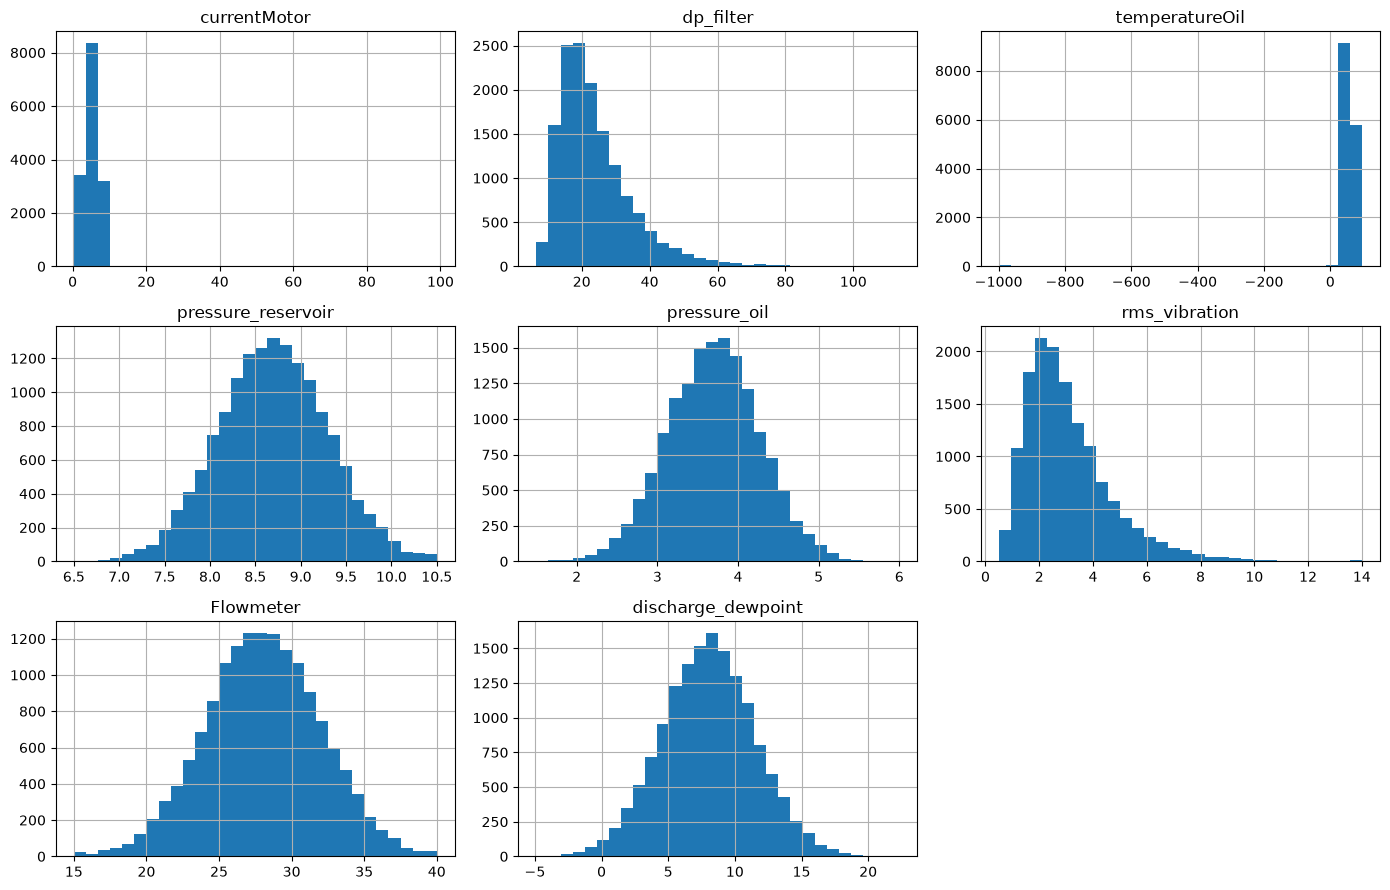

Distributions: units


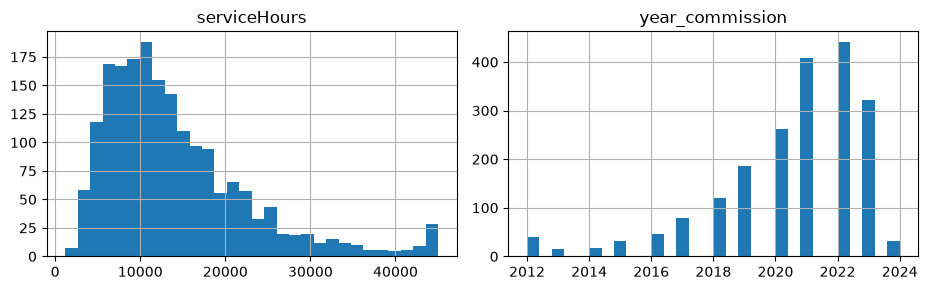

Distributions: gateways


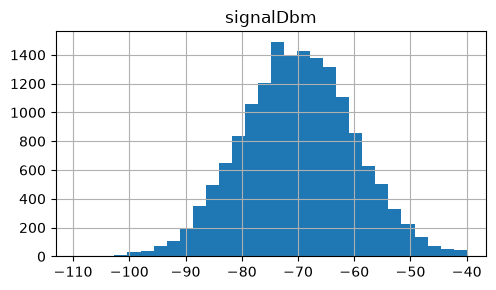

In [8]:
selected_data = [
    ("readings", readings, sensor_attributes),
    ("units", units, unit_attributes),
    ("gateways", gateways, gateway_attributes)
]

for name, df, columns in selected_data:
    print(f"Distributions: {name}")

    df[columns].hist(
        bins=30,
        figsize=(14, 3 * ((len(columns) + 2) // 3)),
        layout=((len(columns) + 2) // 3, 3)
    )

    plt.tight_layout()
    plt.show()

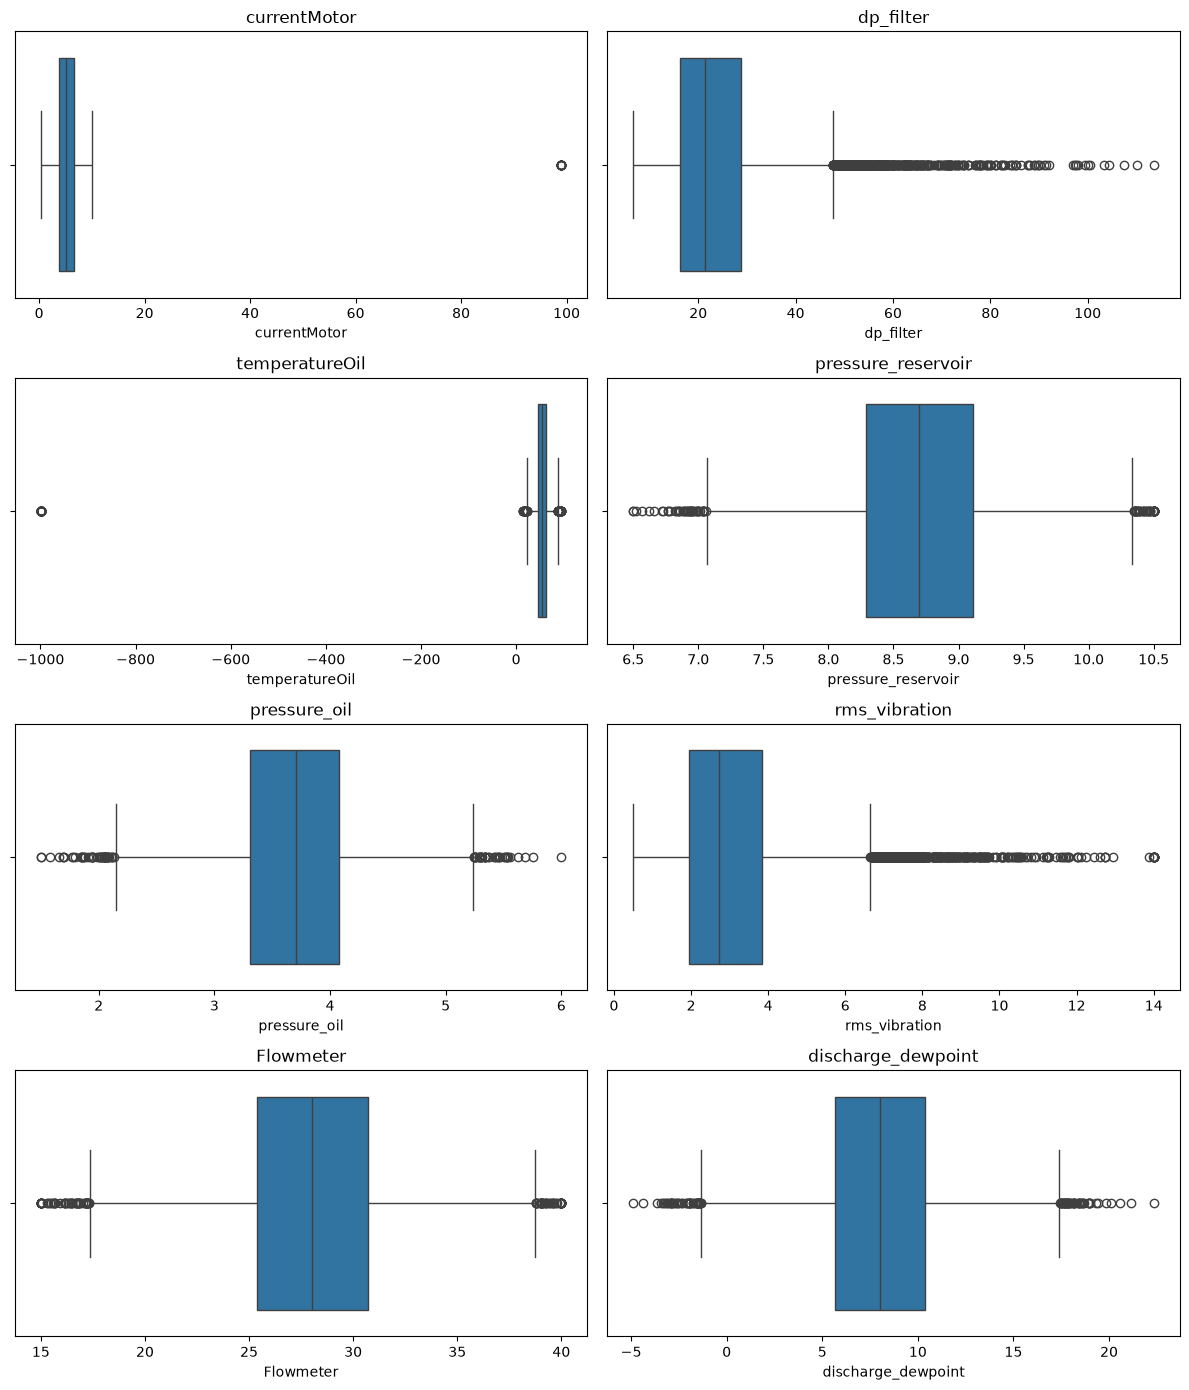

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for ax, column in zip(axes.flatten(), sensor_attributes):
    sns.boxplot(
        x=readings[column],
        ax=ax
    )

    ax.set_title(column)

plt.tight_layout()
plt.show()

In [10]:
range_check = pd.DataFrame({
    "Min": readings[sensor_attributes].min(),
    "Max": readings[sensor_attributes].max(),
    "Negative values": (
        readings[sensor_attributes] < 0
    ).sum(),
    "Missing values": readings[sensor_attributes].isna().sum()
})

display(range_check)

,Min,Max,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0
dp_filter,6.64914,113.55145,0,588
temperatureOil,-999.00000,95.00000,53,0
pressure_reservoir,6.50000,10.50000,0,0
pressure_oil,1.50000,6.00000,0,0
rms_vibration,0.50000,14.00000,0,584
Flowmeter,15.00000,40.00000,0,0
discharge_dewpoint,-4.88825,22.33572,160,0


failure
0    13227
1     1814
Name: count, dtype: int64
failure
0    87.939632
1    12.060368
Name: proportion, dtype: float64


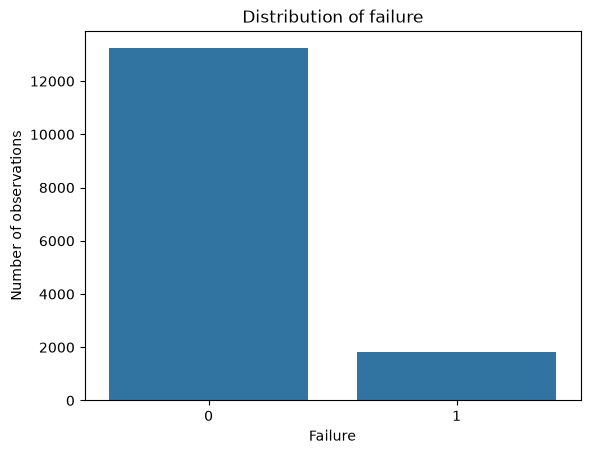

In [11]:
print(readings["failure"].value_counts())
print(readings["failure"].value_counts(normalize=True) * 100)

sns.countplot(
    data=readings,
    x="failure"
)

plt.title("Distribution of failure")
plt.xlabel("Failure")
plt.ylabel("Number of observations")
plt.show()



### Zhodnotenie 1.1(B)

Analyzovali sme 11 vybraných numerických atribútov z troch dátových súborov a cieľovú premennú `failure`.

Pomocou deskriptívnych štatistík, histogramov a boxplotov sme skúmali rozdelenia hodnôt, ich variabilitu a potenciálne odľahlé pozorovania.

V dátach sa nachádzajú chýbajúce hodnoty a podozrivé extrémne hodnoty, napríklad `temperatureOil = -999`. Bez technickej dokumentácie však nie je možné jednoznačne určiť všetky prípustné rozsahy meraní.

Zistili sme tiež nevyvážené rozdelenie cieľovej premennej `failure`, pričom väčšina pozorovaní predstavuje stav bez zlyhania.

Identifikované problémy bude potrebné podrobnejšie preskúmať v časti 1.2.

### C. Párová analýza atribútov

,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint
currentMotor,1.000,0.001,0.001,0.019,0.012,0.006,-0.006,-0.005
dp_filter,0.001,1.000,0.006,-0.001,-0.004,-0.007,-0.006,-0.011
temperatureOil,0.001,0.006,1.000,0.001,0.000,0.006,0.011,-0.002
pressure_reservoir,0.019,-0.001,0.001,1.000,0.852,-0.009,-0.004,-0.003
pressure_oil,0.012,-0.004,0.000,0.852,1.000,-0.002,0.001,-0.010
rms_vibration,0.006,-0.007,0.006,-0.009,-0.002,1.000,-0.011,0.002
Flowmeter,-0.006,-0.006,0.011,-0.004,0.001,-0.011,1.000,-0.004
discharge_dewpoint,-0.005,-0.011,-0.002,-0.003,-0.010,0.002,-0.004,1.000


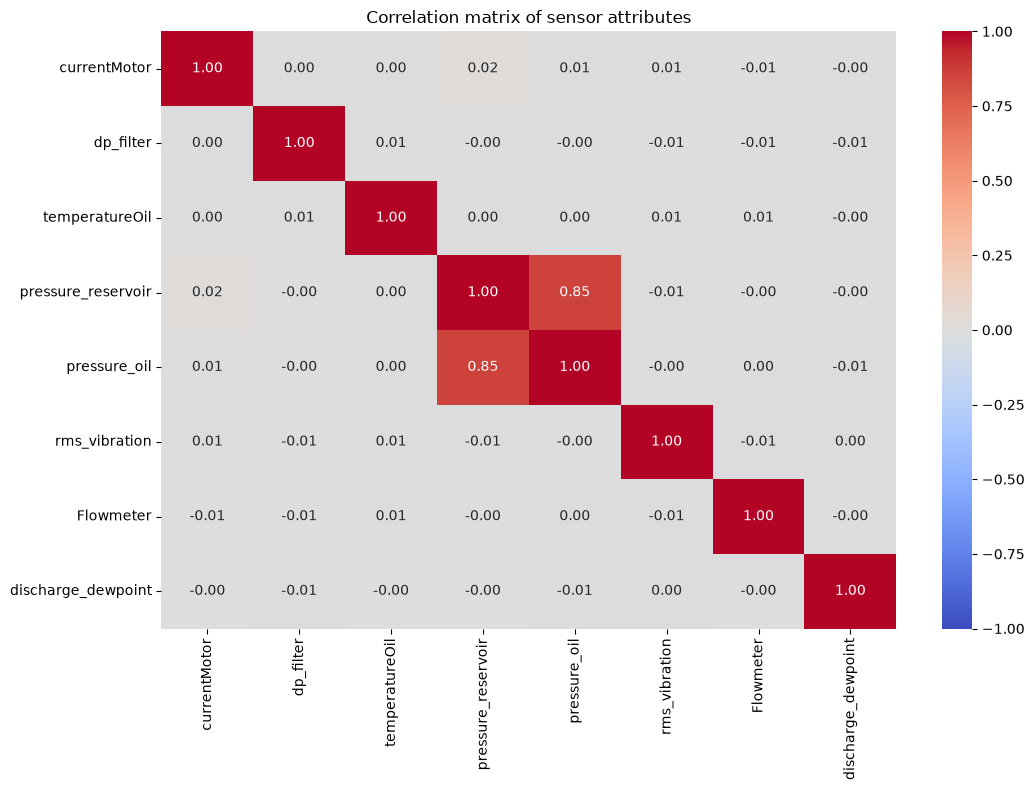

In [12]:
correlation = readings[sensor_attributes].corr()

display(correlation.round(3))

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation matrix of sensor attributes")
plt.tight_layout()
plt.show()

In [13]:
mask = np.triu(
    np.ones(correlation.shape, dtype=bool),
    k=1
)

pairs = correlation.where(mask).stack()

strongest_pairs = pairs.reindex(
    pairs.abs().sort_values(ascending=False).index
)

display(strongest_pairs.head(10))

pressure_reservoir  pressure_oil          0.852449
currentMotor        pressure_reservoir    0.018768
                    pressure_oil          0.012114
dp_filter           discharge_dewpoint   -0.011412
rms_vibration       Flowmeter            -0.011023
temperatureOil      Flowmeter             0.011018
pressure_oil        discharge_dewpoint   -0.010386
pressure_reservoir  rms_vibration        -0.008787
dp_filter           rms_vibration        -0.007339
                    Flowmeter            -0.006383
dtype: float64

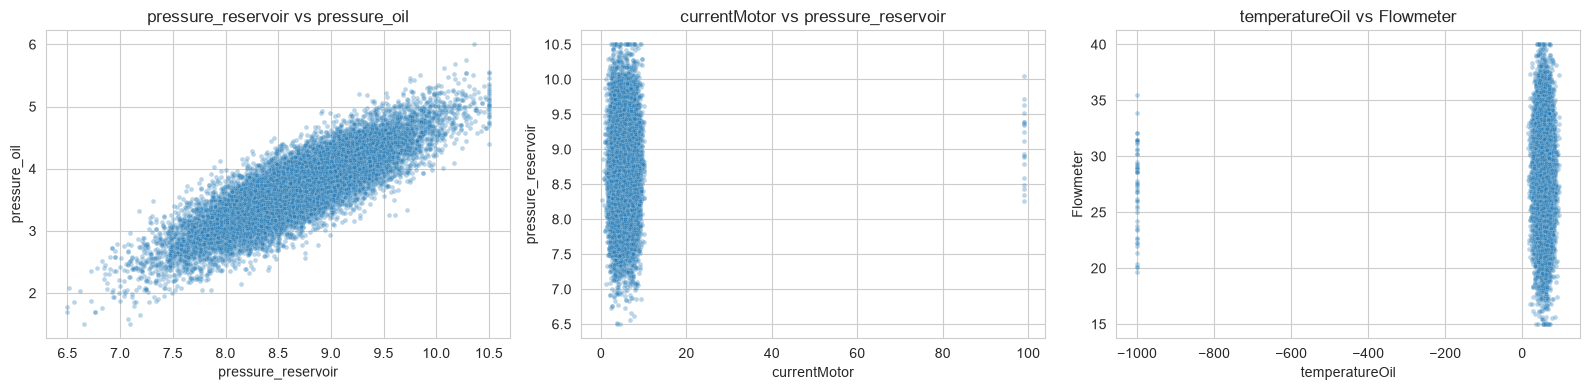

In [40]:
pairs_to_plot = [
    ("pressure_reservoir", "pressure_oil"),
    ("currentMotor", "pressure_reservoir"),
    ("temperatureOil", "Flowmeter")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (x, y) in zip(axes, pairs_to_plot):
    sns.scatterplot(
        data=readings,
        x=x,
        y=y,
        alpha=0.3,
        s=12,
        ax=ax
    )

    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

### Zhodnotenie 1.1(C)

Pomocou korelačnej matice a bodových grafov sme analyzovali vzťahy medzi numerickými senzorovými atribútmi.

Výrazná pozitívna korelácia sa prejavila medzi atribútmi `pressure_reservoir` a `pressure_oil` (približne 0,85). To naznačuje, že vyššie hodnoty jedného atribútu sú často spojené s vyššími hodnotami druhého atribútu.

Takáto závislosť môže byť dôležitá pri následnom výbere atribútov pre strojové učenie. Korelácia však sama osebe neznamená príčinnú súvislosť.

Pred ďalším spracovaním bude tiež potrebné preskúmať vplyv extrémnych hodnôt na vypočítané korelácie.

### D. Závislosti medzi failure a prediktormi

In [15]:
failure_corr = readings[sensor_attributes + ["failure"]].corr()["failure"]

failure_corr = failure_corr.drop("failure")
failure_corr = failure_corr.reindex(
    failure_corr.abs().sort_values(ascending=False).index
)

display(failure_corr.to_frame("Correlation with failure"))
group_stats = readings.groupby("failure")[sensor_attributes].agg(
    ["count", "mean", "median", "std"]
)

,Correlation with failure
dp_filter,0.117892
pressure_reservoir,-0.085653
discharge_dewpoint,0.081442
pressure_oil,-0.077665
rms_vibration,0.059180
Flowmeter,-0.042867
currentMotor,-0.028818
temperatureOil,-0.000780


In [16]:
display(group_stats.T)

failure                               0            1
currentMotor       count   13227.000000  1814.000000
                   mean        5.372459     5.035851
                   median      5.192680     4.661315
                   std         3.837782     3.535804
dp_filter          count   12977.000000  1476.000000
                   mean       23.614772    27.986748
                   median     21.044820    24.920630
                   std        10.864953    13.415976
temperatureOil     count   13227.000000  1814.000000
                   mean       51.279423    51.127040
                   median     55.056980    54.703045
                   std        63.804282    61.998184
pressure_reservoir count   13227.000000  1814.000000
                   mean        8.718318     8.559547
                   median      8.715380     8.540915
                   std         0.600698     0.607249
pressure_oil       count   13227.000000  1814.000000
                   mean        3.713279     3.577169
                   median      3.722730     3.581065
                   std         0.569419     0.566383
rms_vibration      count   12963.000000  1494.000000
                   mean        3.050546     3.369898
                   median      2.697230     2.931705
                   std         1.612011     1.864349
Flowmeter          count   13227.000000  1814.000000
                   mean       28.109172    27.588152
                   median     28.078220    27.551215
                   std         3.965892     3.873561
discharge_dewpoint count   13227.000000  1814.000000
                   mean        7.929126     8.799864
                   median      7.940570     8.738600
                   std         3.461096     3.538583

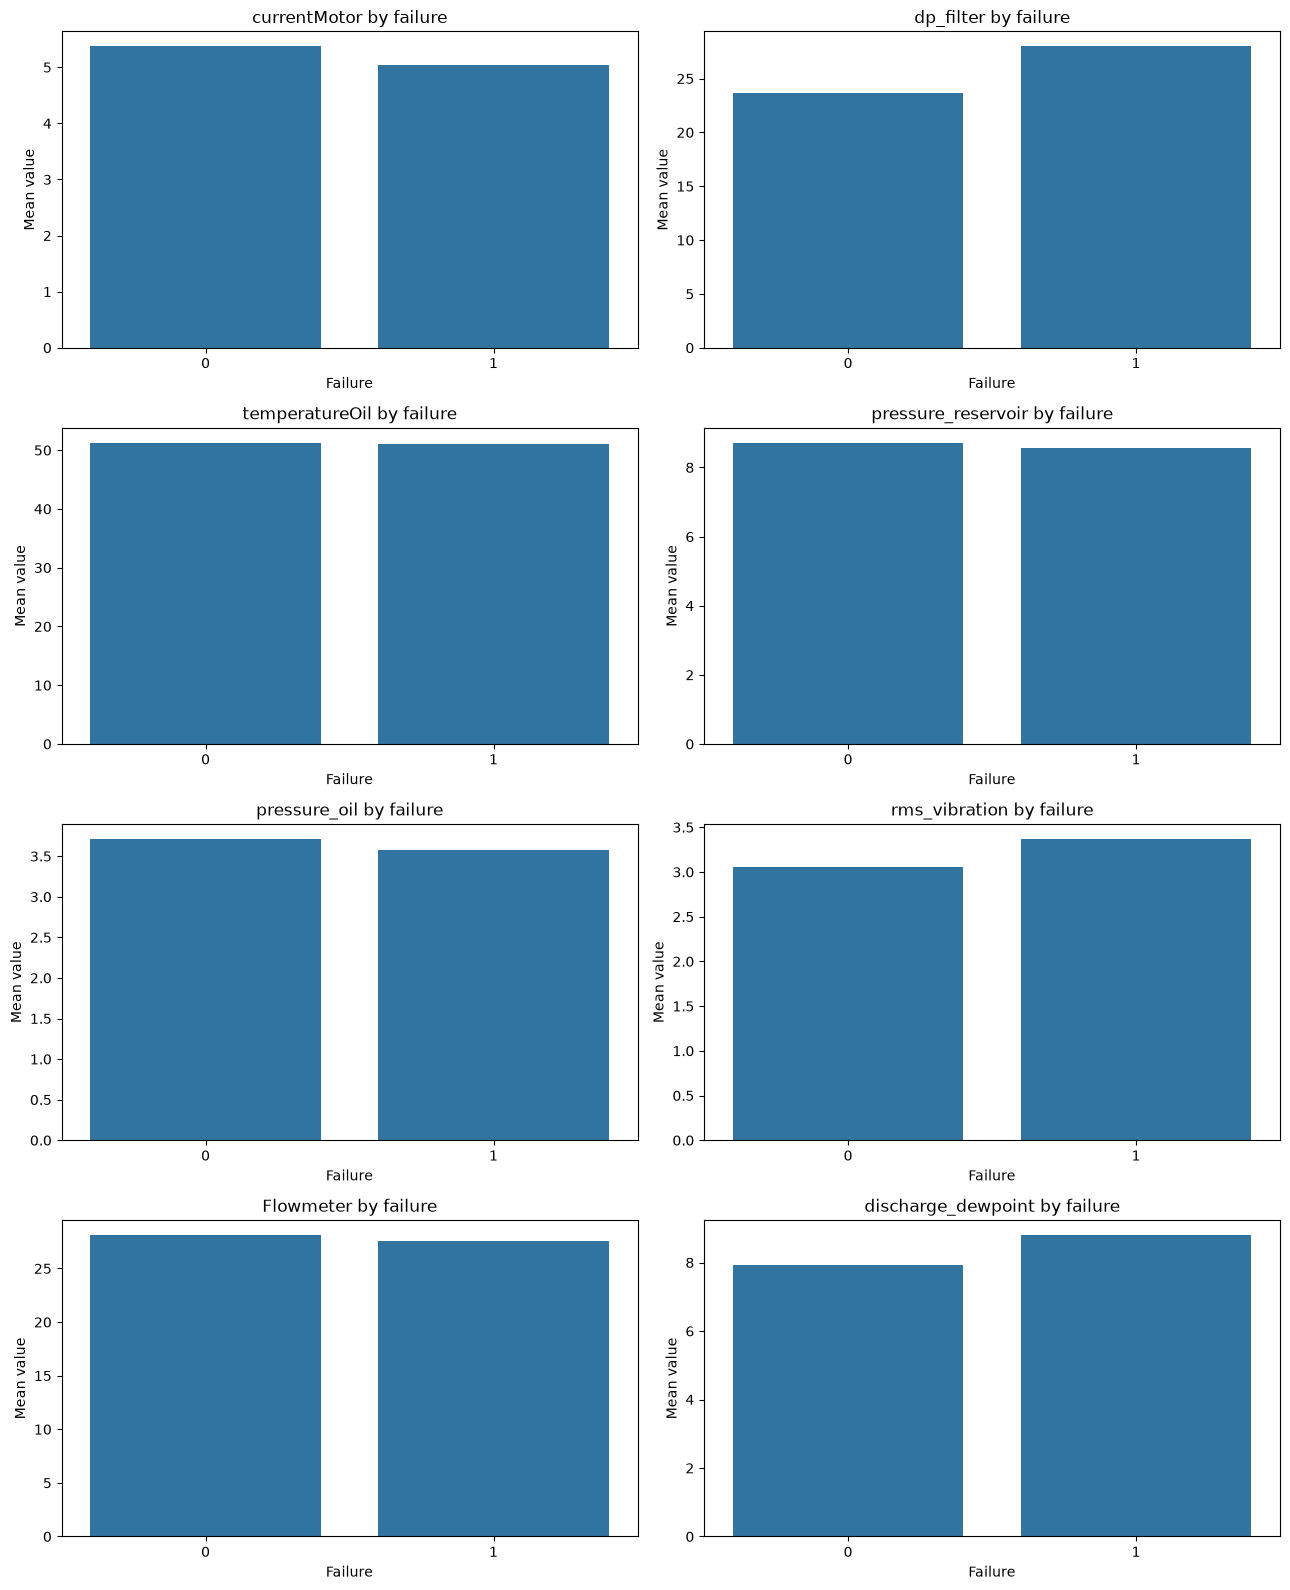

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flatten(), sensor_attributes):
    sns.barplot(
        data=readings,
        x="failure",
        y=column,
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"{column} by failure")
    ax.set_xlabel("Failure")
    ax.set_ylabel("Mean value")

plt.tight_layout()
plt.show()

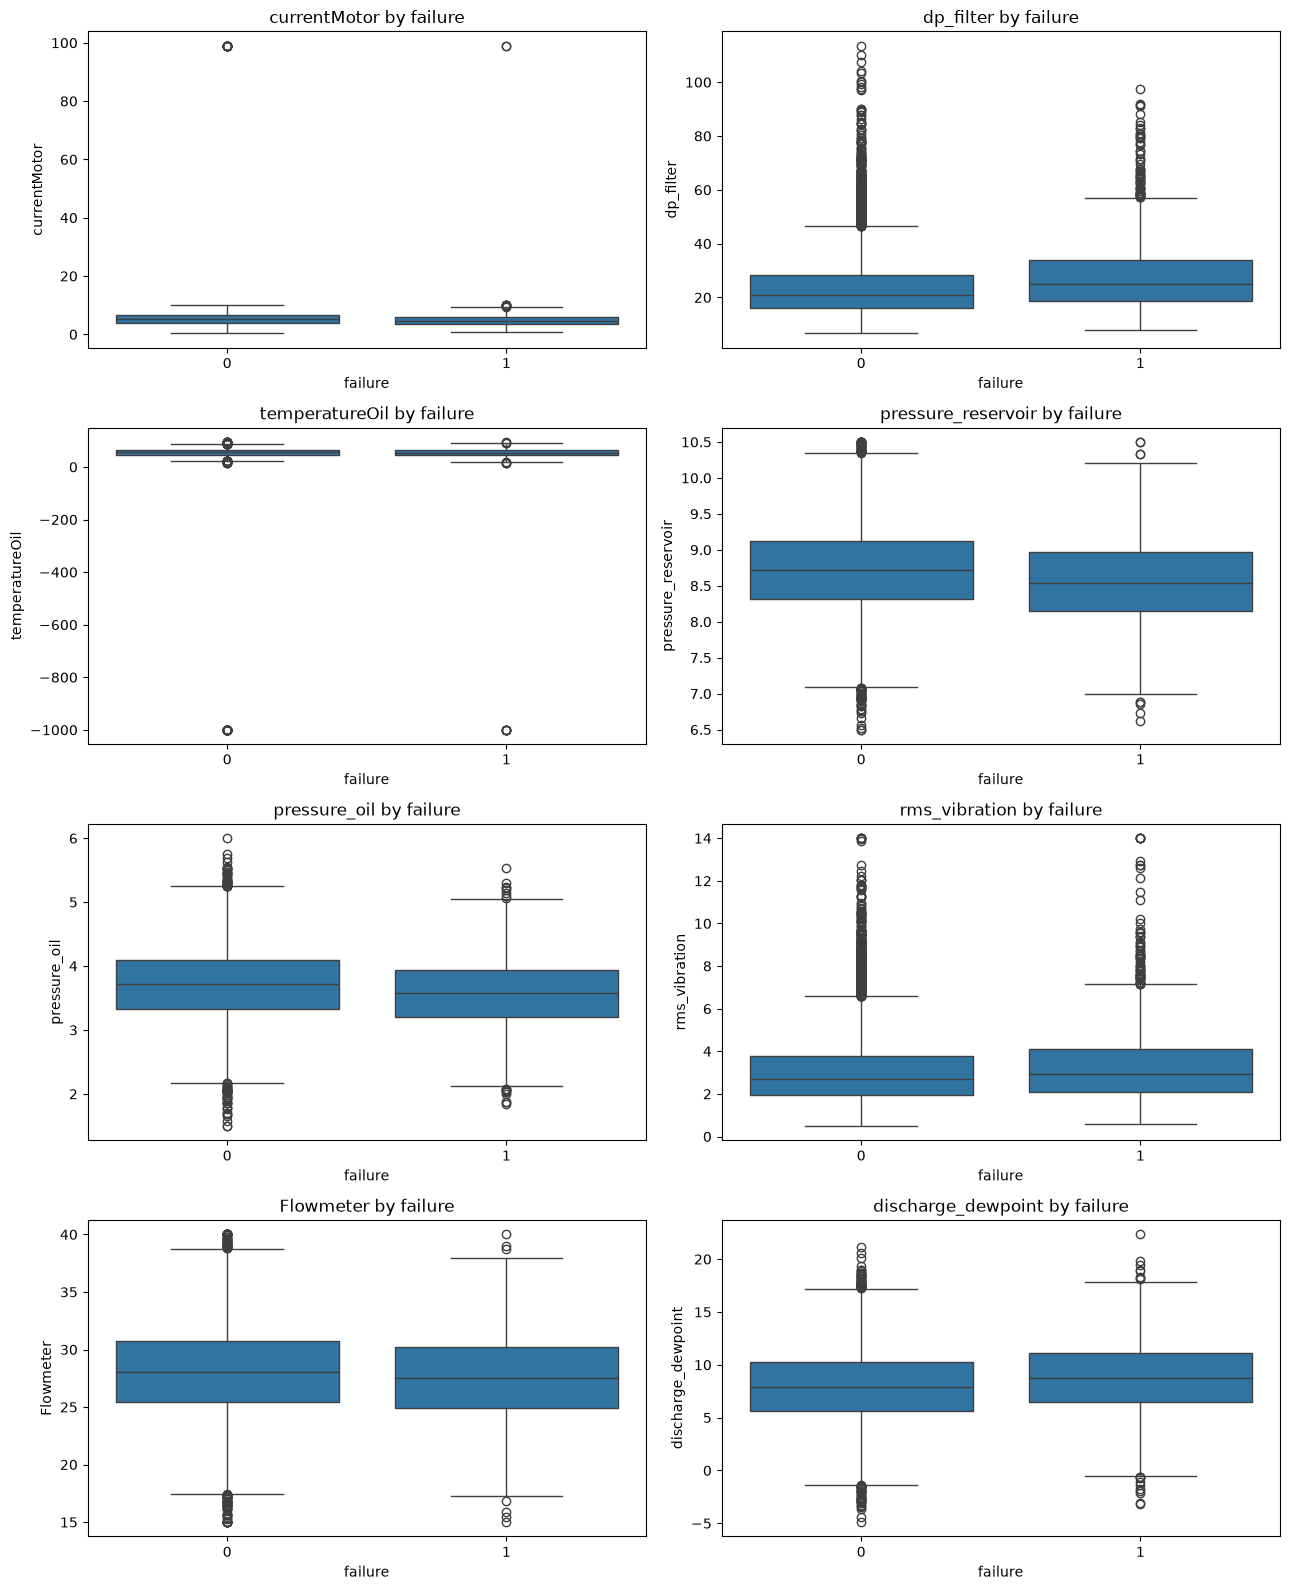

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flatten(), sensor_attributes):
    sns.boxplot(
        data=readings,
        x="failure",
        y=column,
        ax=ax
    )

    ax.set_title(f"{column} by failure")

plt.tight_layout()
plt.show()

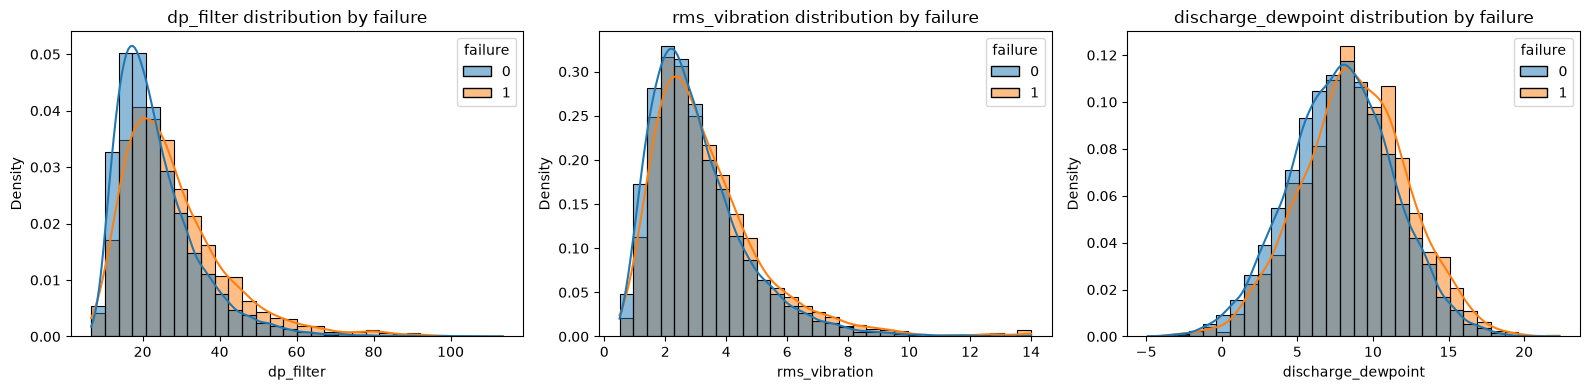

In [19]:
important_attributes = [
    "dp_filter",
    "rms_vibration",
    "discharge_dewpoint"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, important_attributes):
    sns.histplot(
        data=readings,
        x=column,
        hue="failure",
        stat="density",
        common_norm=False,
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f"{column} distribution by failure")

plt.tight_layout()
plt.show()

### Zhodnotenie 1.1(D)

Analyzovali sme vzťahy medzi cieľovou premennou `failure` a jednotlivými senzorovými atribútmi pomocou korelačnej analýzy, porovnania priemerných hodnôt a vizualizácií.

Najvyššiu absolútnu koreláciu s cieľovou premennou dosiahol atribút `dp_filter` (približne 0,118). Ide však o slabú pozitívnu koreláciu.

Pri porovnaní priemerných hodnôt sme zistili, že atribúty `dp_filter`, `rms_vibration` a `discharge_dewpoint` dosahujú vyššie hodnoty pri `failure = 1`. Naopak, hodnoty `pressure_reservoir` a `pressure_oil` sú pri zlyhaní v priemere nižšie.

Tieto výsledky naznačujú, že uvedené atribúty môžu obsahovať informácie užitočné na predikciu zlyhania. Samotné korelácie sú však pomerne slabé, preto bude potrebné preskúmať aj možné nelineárne vzťahy a kombinácie viacerých atribútov.

### E. Prvotné zamyslenie nad riešením

Na základe vykonanej analýzy sme zistili, že niektoré atribúty sú medzi sebou závislé. Napríklad `pressure_reservoir` a `pressure_oil` majú silnú pozitívnu koreláciu (približne 0,85).

Pri analýze cieľovej premennej `failure` sme zistili, že najvýraznejšiu závislosť vykazuje atribút `dp_filter`. Vyššie hodnoty pri zlyhaní sme pozorovali aj pri atribútoch `rms_vibration` a `discharge_dewpoint`. Tieto závislosti sú však pomerne slabé.

Pre ďalšie spracovanie bude pravdepodobne vhodné prepojiť súbory `readings.csv` a `units.csv` pomocou atribútu `idUnit`. Takto môžeme doplniť senzorové merania o informácie o zariadeniach.

V ďalších krokoch sa zameriame na čistenie dát a prípravu atribútov pre strojové učenie.

## 1.2 Identifikácia problémov, integrácia a čistenie dát

### A. Identifikácia a riešenie problémov

In [20]:
units_clean = units.copy()
gateways_clean = gateways.copy()
readings_clean = readings.copy()

print("Original datasets:")
for name, df in datasets.items():
    print(f"{name}: {df.shape}")
def missing_values_table(df):
    missing = pd.DataFrame({
        "Missing count": df.isna().sum(),
        "Missing percentage": df.isna().mean() * 100
    })

    return missing[missing["Missing count"] > 0]


Original datasets:
units: (2000, 9)
gateways: (16000, 14)
readings: (15041, 11)


In [21]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    display(missing_values_table(df))


UNITS


,Missing count,Missing percentage
serviceHours,100,5.0



GATEWAYS


,Missing count,Missing percentage
idUnit,14000,87.5



READINGS


,Missing count,Missing percentage
dp_filter,588,3.909315
rms_vibration,584,3.882721


In [22]:
for name, df in [
    ("units", units_clean),
    ("gateways", gateways_clean),
    ("readings", readings_clean)
]:
    print(f"{name}: {df.duplicated().sum()} duplicates")

units: 0 duplicates
gateways: 0 duplicates
readings: 222 duplicates


In [23]:
readings_clean = readings_clean.drop_duplicates().copy()

print("\nReadings after removing duplicates:")
print(readings_clean.shape)


Readings after removing duplicates:
(14819, 11)


In [24]:
readings_clean["idUnit"] = pd.to_numeric(
    readings_clean["idUnit"].str.extract(r"^U(\d+)$")[0],
    errors="coerce"
).astype("Int64")

units_clean["idUnit"] = units_clean["idUnit"].astype("Int64")

gateways_clean["idUnit"] = gateways_clean["idUnit"].astype("Int64")

print(readings_clean["idUnit"].head())
print(units_clean["idUnit"].head())

print(readings_clean["idUnit"].isna().sum())

0     861
1     339
2    1862
3     659
4     964
Name: idUnit, dtype: Int64
0    1
1    2
2    3
3    4
4    5
Name: idUnit, dtype: Int64
0


In [25]:
gateways_clean["lastSeen"] = pd.to_datetime(
    gateways_clean["lastSeen"],
    format="mixed",
    errors="coerce"
)

gateways_clean["dateInstall"] = pd.to_datetime(
    gateways_clean["dateInstall"],
    format="mixed",
    errors="coerce"
)

readings_clean["tsCycle"] = pd.to_datetime(
    readings_clean["tsCycle"],
    format="mixed",
    errors="coerce"
)

for name, df, column in [
    ("gateways", gateways_clean, "lastSeen"),
    ("gateways", gateways_clean, "dateInstall"),
    ("readings", readings_clean, "tsCycle")
]:
    print(name, column, "NaT:", df[column].isna().sum())

gateways lastSeen NaT: 0
gateways dateInstall NaT: 0
readings tsCycle NaT: 0


In [26]:
print(
    "Before:",
    (readings_clean["temperatureOil"] == -999).sum()
)

readings_clean["temperatureOil"] = (
    readings_clean["temperatureOil"].replace(-999, np.nan)
)

print(
    "After:",
    (readings_clean["temperatureOil"] == -999).sum()
)

print(
    "Missing temperatureOil:",
    readings_clean["temperatureOil"].isna().sum()
)

Before: 49
After: 0
Missing temperatureOil: 49


In [27]:
reading_missing_cols = [
    "dp_filter",
    "rms_vibration",
    "temperatureOil"
]

for col in reading_missing_cols:
    median_value = readings_clean[col].median()

    readings_clean[col] = readings_clean[col].fillna(
        median_value
    )

    print(f"{col}: filled with median {median_value:.3f}")


median_hours = units_clean["serviceHours"].median()

units_clean["serviceHours"] = (
    units_clean["serviceHours"].fillna(median_hours)
)

print("\nMissing values after filling:")
display(missing_values_table(readings_clean))
display(missing_values_table(units_clean))

dp_filter: filled with median 21.355
rms_vibration: filled with median 2.717
temperatureOil: filled with median 55.075

Missing values after filling:


,Missing count,Missing percentage


,Missing count,Missing percentage


In [28]:
print("Before cleaning:")
print(units_clean["dutyClass"].value_counts())

Before cleaning:
dutyClass
1           251
light       249
L           229
heavy       173
N           159
H           157
2           152
med         149
normal      141
3           133
 1           30
 light       29
 N           27
 heavy       23
 L           22
 3           20
 normal      17
 H           15
 med         15
 2            9
Name: count, dtype: int64


In [41]:
units_clean["dutyClass"] = (
    units_clean["dutyClass"]
    .str.strip()
    .str.lower()
)

print("\nAfter cleaning:")
print(units_clean["dutyClass"].value_counts())


After cleaning:
dutyClass
1         281
light     278
l         251
heavy     196
n         186
h         172
med       164
2         161
normal    158
3         153
Name: count, dtype: int64


In [42]:
merged_data = readings_clean.merge(
    units_clean,
    on="idUnit",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("", "_unit")
)

print("Readings:", len(readings_clean))
print("Merged:", len(merged_data))

print("\nMerge results:")
display(merged_data["_merge"].value_counts())

merged_data = merged_data.drop(columns=["_merge"])

Readings: 14819
Merged: 14819

Merge results:


_merge
both          14679
left_only       140
right_only        0
Name: count, dtype: int64

In [30]:
display(merged_data.head())

,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure,year_commission,operatorOwner,number_serial,idDepot,codeLine,serviceHours,code_model,dutyClass
0,861,2023-01-24 00:00:00,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0,2021.0,Smith Inc,YF-9652-68924,33.0,L6,11660.4,APU-15,l
1,339,2023-03-23 00:00:00,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0,2021.0,Speer Aumann GmbH & Co. KG,DV-8136-59323,2.0,L5,13438.9,XC-7,light
2,1862,2023-01-02 00:00:00,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0,2023.0,Smith Inc,RZ-8097-07999,67.0,L3,6663.4,APU-20,1
3,659,2023-11-27 00:00:00,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1,2017.0,Killer Ladeck GmbH & Co. KG,FB-1611-52787,12.0,L4,24578.2,APU-15,1
4,964,2023-12-30 22:08:00,7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0,2017.0,"Bryant, Williams and Roberts",RJ-8551-19225,29.0,L1,26640.5,APU-20,h


### Zhodnotenie 1.2(A)

Pri analýze dát sme identifikovali niekoľko problémov, medzi ktoré patria chýbajúce hodnoty, duplicitné záznamy, nejednotné formáty dátumov a identifikátorov, ako aj podozrivé extrémne hodnoty.

V súbore `readings.csv` sme identifikovali 222 úplne duplicitných záznamov, ktoré sme odstránili. Formát identifikátora `idUnit` sme zjednotili medzi jednotlivými súbormi a dátumové atribúty sme skonvertovali na dátumový typ.

Hodnoty `temperatureOil = -999` sme považovali za neplatné merania a nahradili ich chýbajúcimi hodnotami. Na doplnenie chýbajúcich numerických hodnôt sme v tejto fáze použili medián jednotlivých atribútov.

Zároveň sme upravili zápis kategórií v atribúte `dutyClass` odstránením nadbytočných medzier a zjednotením veľkosti písmen.

Následne sme prepojili súbory `readings.csv` a `units.csv` pomocou atribútu `idUnit`. Použili sme left join, aby sme zachovali aj merania bez zodpovedajúceho záznamu o zariadení.

Pri ďalšom spracovaní bude potrebné zabezpečiť, aby sa parametre čistenia a imputácie určovali iba z trénovacích dát.

### B. Kontrola správnosti dát

In [43]:
sensor_check_before = pd.DataFrame({
    "Min": readings[sensor_attributes].min(),
    "Max": readings[sensor_attributes].max(),
    "Zero values": (readings[sensor_attributes] == 0).sum(),
    "Negative values": (readings[sensor_attributes] < 0).sum(),
    "Missing values": readings[sensor_attributes].isna().sum()
})

sensor_check_after = pd.DataFrame({
    "Min": readings_clean[sensor_attributes].min(),
    "Max": readings_clean[sensor_attributes].max(),
    "Zero values": (readings_clean[sensor_attributes] == 0).sum(),
    "Negative values": (readings_clean[sensor_attributes] < 0).sum(),
    "Missing values": readings_clean[sensor_attributes].isna().sum()
})

print("Before cleaning:")
display(sensor_check_before)

Before cleaning:


,Min,Max,Zero values,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0,0
dp_filter,6.64914,113.55145,0,0,588
temperatureOil,-999.00000,95.00000,0,53,0
pressure_reservoir,6.50000,10.50000,0,0,0
pressure_oil,1.50000,6.00000,0,0,0
rms_vibration,0.50000,14.00000,0,0,584
Flowmeter,15.00000,40.00000,0,0,0
discharge_dewpoint,-4.88825,22.33572,0,160,0


In [44]:
print("After cleaning:")
display(sensor_check_after)

After cleaning:


,Min,Max,Zero values,Negative values,Missing values
currentMotor,0.33561,99.00000,0,0,0
dp_filter,6.64914,113.55145,0,0,0
temperatureOil,15.00000,95.00000,0,0,0
pressure_reservoir,6.50000,10.50000,0,0,0
pressure_oil,1.50000,6.00000,0,0,0
rms_vibration,0.50000,14.00000,0,0,0
Flowmeter,15.00000,40.00000,0,0,0
discharge_dewpoint,-4.88825,22.33572,0,156,0


In [46]:
invalid_dates = (
    gateways_clean["lastSeen"] <
    gateways_clean["dateInstall"]
)

print("Gateways with lastSeen before dateInstall:")
print(invalid_dates.sum())

display(
    gateways_clean.loc[
        invalid_dates,
        ["id_gateway", "dateInstall", "lastSeen"]
    ].head(10)
)

duplicate_measurements = readings_clean.duplicated(
    subset=["idUnit", "tsCycle"],
    keep=False
)

print("Rows sharing unit and timestamp:")
print(duplicate_measurements.sum())

Gateways with lastSeen before dateInstall:
721


,id_gateway,dateInstall,lastSeen
7,GW-00007,2024-09-03,2024-07-16
11,GW-00011,2024-11-13,2024-06-08
41,GW-00041,2024-08-03,2024-04-30
67,GW-00067,2024-11-11,2024-03-26
83,GW-00083,2024-04-10,2024-01-23
115,GW-00115,2024-06-02,2024-02-16
117,GW-00117,2024-11-23,2024-09-30
132,GW-00132,2024-07-24,2024-05-15
133,GW-00133,2024-10-14,2024-10-11
137,GW-00137,2024-08-22,2024-01-04


Rows sharing unit and timestamp:
161


In [47]:

display(
    readings_clean.loc[duplicate_measurements]
    .sort_values(["idUnit", "tsCycle"])
    .head(20)
)

print("Failure values:")
print(readings_clean["failure"].value_counts(dropna=False))

invalid_failure = ~readings_clean["failure"].isin([0, 1])

print("Invalid failure values:", invalid_failure.sum())

,idUnit,tsCycle,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure
2674,24,2023-05-01,3.26378,18.28350,68.87724,9.10262,4.23268,3.492480,31.87744,12.18193,0
6143,24,2023-05-01,3.35807,22.13903,53.11614,9.33545,4.19346,2.116730,22.74323,5.03497,0
5752,33,2023-06-24,4.82756,17.56122,46.09724,9.41263,4.21727,1.695950,28.26960,8.17711,0
13271,33,2023-06-24,6.58982,17.34402,70.90096,8.05656,3.04276,2.229760,15.00000,7.88986,0
5749,37,2023-11-26,4.74459,23.16488,68.89369,8.00559,3.98054,3.087230,21.97706,11.72689,0
9985,37,2023-11-26,4.00420,13.40114,70.37491,8.11847,3.87498,1.796610,25.94196,6.42388,0
945,38,2023-03-15,3.87714,41.39966,46.83104,7.90196,2.55956,2.018990,25.90530,11.00236,0
14239,38,2023-03-15,4.32318,19.19209,64.09954,8.94048,3.54762,2.716745,30.03639,9.30244,0
6647,42,2023-09-06,5.38121,14.09272,58.88258,9.05072,4.10280,2.114160,25.26607,9.84881,0
9495,42,2023-09-06,5.16616,21.94164,57.64266,9.21467,3.79342,8.791570,23.60840,2.71920,0


Failure values:
failure
0    13026
1     1793
Name: count, dtype: int64
Invalid failure values: 0


### Zhodnotenie 1.2(B)

Pri kontrole správnosti dát sme sa zamerali na identifikáciu abnormálnych hodnôt a nelogických vzťahov medzi atribútmi.

V senzorových dátach sme identifikovali podozrivé hodnoty, napríklad `temperatureOil = -999`, ktoré sme v predchádzajúcej časti nahradili chýbajúcimi hodnotami. Niektoré ďalšie atribúty obsahujú extrémne hodnoty, pri ktorých bude potrebné overiť, či ide o skutočné merania alebo chyby.

Pri kontrole dátumov v súbore `gateways.csv` sme zistili **721 záznamov**, v ktorých je dátum poslednej komunikácie (`lastSeen`) skorší ako dátum inštalácie (`dateInstall`). Ide o potenciálne nelogický vzťah, ktorý môže byť spôsobený nesprávnym zaznamenaním alebo interpretáciou dátumov.


V súbore `readings.csv` sme identifikovali viacero meraní pre rovnaké zariadenie a dátum. Tieto záznamy sme neodstraňovali, pretože môžu predstavovať samostatné merania v rámci jedného dňa.

Nakoniec sme overili hodnoty cieľovej premennej `failure`. Po odstránení úplných duplicít obsahuje **13 026 záznamov s hodnotou 0 a 1 793 záznamov s hodnotou 1**. Neplatné hodnoty sme nezistili.

Identifikované problémy ukazujú, že pred ďalším spracovaním je potrebné venovať pozornosť najmä časovej konzistentnosti údajov a rozlišovaniu medzi skutočnými extrémnymi hodnotami a chybami merania.

### C. Detekcia a riešenie odľahlých hodnôt